# AI 选股信号该配多大仓位？——虚拟仿真下的风险预算干预实验

**摘要**：大模型投研台普及，但“AI 说了买”之后**该买多少**少有系统训练。本案例以 28 只沪深蓝筹、410 个交易日真实公开行情为沙盘构建受控仿真，透明注入 6910 条固定种子 AI 信号，冻结信号、只变仓位规则（满仓等权、置信度分档、1/4 凯利+干预），在 5bp 成本、6% 回撤预算下做多策略对照，辅以样本外与反事实检验。发现：满仓组成本年化拖累 8.8%，风险预算组以一半换手把回撤从 -12.4% 压到 -9.3%；置信度均值 0.87、真实命中约 54%，再校准修得好“说的”、修不了“知的”；成本扫描显示排序随成本反转。学生以“风险预算官”身份亲历可验证、可复核、可追溯的决策纪律。

**关键词**：虚拟仿真；AI选股；仓位决策；风险预算；样本外检验

> **数据说明（重要）**：本案例为虚拟仿真实验。行情数据取自腾讯财经公开行情接口（前复权日线，2024-01-02 至 2025-10-28，28 只沪深大盘蓝筹，代码与名单见 2.1 节），**行情是真实的公开数据，出处明确、可重新下载核验**；AI 信号为实验条件，由附件 `gen_signals.py` 以透明蒙特卡洛规则注入（方向命中率 55% 的假设、随机种子 20261029 固定、全程可复现）。教学目标是训练**仓位决策**能力：真实行情保证环境的复杂性，透明信号保证实验的可控性，二者结合才构成完整的虚拟仿真沙盘。

## 案例资源

**资源简介**：本案例的资源是一条可复现的“数据 → 信号 → 规则 → 检验 → 建议”链路。研究逻辑：真实公开行情（腾讯财经接口）→ 透明信号注入（种子 20261029）→ 三组仓位规则受控对照 → 样本外检验、敏感性、反事实、成本扫描、再校准闭环、信号衰减、因子化诊断 → 结论与建议。数据规则与实验设计分别见 1.4 节数据规则说明表与 1.5 节实验设计表。

| 资源 | 内容 | 说明 |
| --- | --- | --- |
| prices.csv | 28 只沪深大盘蓝筹前复权收盘价，410 个交易日 | 11480 行，可重新下载核验 |
| signals.csv | 模拟 AI 买/卖信号与置信度 | 6910 条，种子 20261029 |
| fetch_prices.py / gen_signals.py | 行情下载与信号注入脚本 | 生成规则完全公开 |
| run_all.py | 实验管线一键复现 | 输出 summary.json |
| vx_verify.py | 24 锚点一键自检 + manifest 数字出生证明 | 输出 results/manifest.json |

## 推荐工具说明

本案例全部计算在平台在线 Notebook（Python 3 / ipykernel）内完成，无需本地安装。涉及的第三方包及版本：

| 工具 | 用途 | 版本要求 |
| --- | --- | --- |
| Python | 运行环境 | ≥ 3.8（平台内置） |
| pandas | 数据读取、面板构建、回测引擎 | ≥ 1.3 |
| numpy | 数值计算（收益、秩相关、自助法） | ≥ 1.21 |
| matplotlib | 全部图形绘制（净值、回撤、敏感性） | ≥ 3.5 |

如需本地复现，建议使用 Anaconda 或 Miniconda 管理环境：

```bash
conda create -n zhixiang python=3.10 pandas numpy matplotlib -y
conda activate zhixiang
python run_all.py
python vx_verify.py
```

平台右侧“代码帮助”面板提供常用代码片段；“AI 助手”面板可进行代码诊断。遇到报错时，先检查数据文件路径与工作目录是否一致，再核对随机种子是否为 20261029。


## 0 使用指南

### 0.1 三种使用模式

| 模式 | 适合人群 | 做法 |
| --- | --- | --- |
| 顺序精读 | 首次学习 | 逐单元运行并阅读，重点理解 1.3 与 4.1 |
| 直接运行 | 复习/复核 | "运行→全部运行"约 2 分钟，回读重点小节 |
| 只看结论 | 快速浏览 | 读 5 结论 + 附录 |

### 0.2 学习目标（完成本案例后应能做到）

- 说出仓位规则在"信号→仓位→后果"链条中的位置（K1）
- 解释 5bp 成本为何形成约 8.8% 年化拖累（K2）
- 依据校准表指出置信度过度自信（K3）
- 说明 1/4 凯利与触线干预的双重属性（K4）
- 独立设计仓位规则并完成对照回测（A2）
- 用敞口匹配基准检验自己的结论（4.10）

### 0.3 术语表

| 术语 | 含义 | 出处 |
| --- | --- | --- |
| 前复权 | 分红送股调整到当前口径 | 2.1 |
| 超额收益 | 个股−等权指数 | 3 |
| 凯利分数 | f*=(p·b−q)/b | 4.1 |
| 1/4 缩放 | 凯利×0.25 保守化 | 4.1 |
| 最大回撤 | 峰值到谷底最大跌幅 | 4.1 |
| 卡玛比率 | 年化/回撤 | 4.3 |
| 样本外 | 后 30% 检验段 | 1.4 |
| 反事实 | 移除机制重跑 | 4.5 |
| 置信度校准 | 置信度 vs 真实频率 | 4.1 |
| IC | 信号 vs 收益秩相关 | 4.9 |
| ICIR | IC 均值/标准差 | 4.9 |
| 块状自助法 | 时间块重抽样 CI | 4.11 |
| 凸性冲击 | 成本含换手平方项 | 4.11 |
| walk-forward | 仅用历史重估 | 4.11 |

## 1 引言

### 1.1 研究背景与意义

证券公司、基金公司正在批量引入大模型投研工作台：每日对数百只标的给出看多/看空观点与置信度。信号"准不准"已被大量研究讨论，但**信号"配多大仓位"**——即信号到资金之间的转化规则——才是直接决定账户损益与回撤的环节。现实中，这一环节往往依赖交易员经验，缺乏可训练、可考核、可复现的实验环境。

本案例的意义在于：把"AI 选股 → 仓位决策 → 风险后果"的完整链条搬进虚拟仿真沙盘，让学生在零真实资金风险的条件下，亲身体会三条朴素但常被忽视的规律：

1. **预测力 ≠ 盈利能力**：方向命中率 55% 的信号，既可能做出高收益，也可能被交易成本与回撤吞没，分水岭在仓位规则；
2. **风险预算是约束，更是干预工具**：它不仅是"不能超过"的红线，还是可以主动触发降仓的机制；
3. **AI 的置信度不是仓位权重**：未经校准的置信度直接映射仓位，会把模型的过度自信放大为账户的过度敞口。

### 1.2 研究目的

本案例要求学生以**风险预算官**的身份完成四项任务：

- **任务一（描述）**：诊断 AI 信号的统计特征与置信度校准质量；
- **任务二（实验）**：在同一信号下设计三种仓位规则，构建对照实验；
- **任务三（检验）**：进行样本外检验、参数敏感性分析与反事实分析，回答"风险预算干预到底值多少钱"；
- **任务四（决策）**：在给定硬约束（5bp 成本、6% 回撤预算、20% 个股上限）下，给出仓位配置建议并论证。

### 1.3 实验任务书（教师统一发布，学生不得修改硬参数）

> 你是某券商资管条线的**风险预算官**。大模型投研工作台每日收盘后对股票池输出买/卖观点及置信度（0–1）。你的职责不是判断信号对错（信号由 AI 生成、已冻结），而是设计"信号 → 仓位"的转化规则，使组合在给定风险预算内尽可能高效地把预测力转化为收益。
>
> **规则约束**：单边交易成本 5bp；单一标的上限 20%；总仓位上限 100%——这三项为硬约束，违反即方案无效；**回撤触线 -6% 为软干预线**：触及即仓位减半，它降低回撤概率但不保证回撤不突破预算（本案例的结果即如此，见 4.10 节的讨论）。
>
> **交付物**：①信号诊断报告（统计特征 + 置信度校准表）；②仓位规则设计说明（含对照组）；③全样本与样本外绩效对比表；④参数敏感性与反事实分析报告；⑤一页纸仓位配置建议。

### 1.4 数据规则说明表

| 项目 | 规则 | 说明 |
| --- | --- | --- |
| 行情来源 | 腾讯财经公开行情接口 | 前复权日线收盘价，真实公开数据，可重新下载核验 |
| 股票池 | 28 只沪深大盘蓝筹 | 名单见 2.1 节；样本期 2024-01-02 至 2025-10-28，共 410 个交易日 |
| 信号来源 | 透明蒙特卡洛模拟（`gen_signals.py`，种子 20261029） | 方向 = 次日超额收益符号以 55% 概率取对；**信号是实验条件，不是真实 AI 产品输出** |
| 置信度 | 与真实超额幅度正相关 + 噪声 | 故意保留校准误差（过度自信），作为实验诊断素材 |
| 样本划分 | 前 70% 样本内（估计参数）/ 后 30% 样本外（检验结论） | 任何参数不得使用样本外信息 |

### 1.5 实验设计表

| 环节 | 设计 | 目的 |
| --- | --- | --- |
| 对照组 A | 有信号即满仓等权，无风险预算 | 锚定"直觉做法"的基准 |
| 实验组 B | 置信度分档固定分数（≥0.7→30%，0.55–0.7→20%） | 检验"置信度直接映射仓位"是否可行 |
| 实验组 C | 样本内估计凯利分数 × 1/4 + 回撤触线减半 | 定量风险预算 + 主动干预 |
| 样本外检验 | 参数不动，回测起点移至 70% 分位 | 检验结论稳健性 |
| 敏感性分析 | 凯利缩放 1/8、1/4、1/2、1 × 干预有无（全样本） | 识别结论成立的参数范围（含反事实） |
| 干预线敏感性 | 回撤预算线 -3%、-6%、-9%（1/4 凯利） | 回答"预算线设在哪里" |

**预期结果与评分提示**：本实验结果不唯一——干预规则的设计空间是开放的（触线减半只是示例），不同设计应得出不同结论并接受数据检验。评分侧重**过程可追溯**（每个数字可由代码复现）与**解释合理性**（结论与证据匹配），而非收益率高低。

### 1.6 典型错误引导（实验前必读）

1. **前视偏差**：信号在 t 日收盘后生成，只能作用于 t+1 及以后的收益；直接把信号对齐到 t 日收益会让所有策略"虚高"。
2. **忽略交易成本**：5bp 看似微小，但满仓组日均换手约 0.70，年化拖累约 8.8 个百分点——不做成本扣除的回测没有讨论价值。
3. **过拟合凯利分数**：凯利估计必须用样本内数据；若用全样本估计，等于偷看答案。
4. **只报有利结果**：只展示"干预有效"的情形是选择性报告；本案例要求同时报告反事实（移除干预）的结果。

## 2 数据获取与预处理

### 2.1 数据来源

实验使用两份配套数据集（本案例"数据集"栏目已上传，附件含完整复现代码）：

| 文件 | 内容 | 字段说明 |
| --- | --- | --- |
| `prices.csv` | 28 只沪深大盘蓝筹 **410 个交易日**前复权收盘价（2024-01-02 至 2025-10-28） | `date` 交易日；`code` 证券代码（sh600519 等）；`close` 收盘价 |
| `signals.csv` | 大模型投研工作台每日选股信号（**实验条件，透明模拟**） | `date` 信号日（收盘后生成）；`code` 标的；`signal` 买/卖；`conviction` 置信度 0–1 |

股票池（28 只，兼顾金融、消费、能源、制造、科技的沪深蓝筹）：贵州茅台、中国平安、招商银行、兴业银行、长江电力、紫金矿业、中信证券、中国银行、恒瑞医药、隆基绿能、伊利股份、中国神华、中国石化、中国石油、通威股份、陕西煤业、万华化学、海尔智家、中远海控、国电南瑞、工业富联、中国联通、海螺水泥、中国铝业、宝钢股份、国泰海通、招商证券、中信建投。

**行情是真实的公开数据**（腾讯财经公开行情接口，前复权），出处明确、任何学生可重新下载核验；**信号是透明模拟的实验条件**——方向以 55% 概率命中次日超额收益（随机种子 20261029，实测命中率 53.95%），置信度由真实超额幅度线性映射叠加噪声生成，**故意保留校准误差**作为实验素材。附件 `fetch_prices.py` 与 `gen_signals.py` 完整记录生成过程。

### 2.2 数据预处理

预处理目标有三：一是把长表数据展开为"日期 × 标的"矩阵，便于矩阵化回测；二是把信号生效时间对齐到"收盘后、次日收益前"，杜绝前视偏差；三是剔除末日无效信号。

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 中文字体（平台实验环境已内置；本地运行时如缺字体可删除这两行）
plt.rcParams["font.sans-serif"] = ["PingFang SC", "Hiragino Sans GB", "Arial Unicode MS", "Noto Sans CJK SC", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False

# ---- 实验硬参数（教师统一设定，学生不得修改）----
TC_BP   = 5.0     # 单边交易成本 5bp（约等于 A 股佣金+冲击成本的经验水平）
MAX_DD  = 0.06    # 风险预算：最大回撤干预线 6%
CAP     = 0.20    # 单一标的上限 20%
RF      = 0.02    # 无风险利率 2%
OOS     = 0.70    # 前 70% 为样本内，后 30% 为样本外

# 定位数据集（平台上传后自动出现在工作目录）
DATA_DIR = None
for cand in ["dataset", "./dataset", ".", "/home/jovyan/dataset", "/home/jovyan"]:
    if os.path.exists(os.path.join(cand, "prices.csv")) and os.path.exists(os.path.join(cand, "signals.csv")):
        DATA_DIR = cand
        break
assert DATA_DIR, "未找到 prices.csv / signals.csv，请先上传数据集"
print("数据集已定位：prices.csv + signals.csv（行情 28 只 × 410 天；信号 6910 条）")

数据集已定位：prices.csv + signals.csv（行情 28 只 × 410 天；信号 6910 条）


In [2]:
px = pd.read_csv(os.path.join(DATA_DIR, "prices.csv"), parse_dates=["date"])
sg = pd.read_csv(os.path.join(DATA_DIR, "signals.csv"), parse_dates=["date"])

# 收盘价面板与日收益面板
pivot = px.pivot(index="date", columns="code", values="close").sort_index()
rets  = pivot.pct_change().fillna(0.0)

# 信号表清洗：排序、剔除末日信号（次日无收益）、方向数字化
sg = sg.sort_values(["date", "code"]).reset_index(drop=True)
sg = sg[sg["date"] < pivot.index[-1]]
sg["dir"] = sg["signal"].map({"buy": 1, "sell": -1})

dates = pivot.index
T, N  = rets.shape
codes = list(pivot.columns)
c2i, d2i = {c: i for i, c in enumerate(codes)}, {d: i for i, d in enumerate(dates)}

# 展开成矩阵：sig_mat[t, j] 为 t 日收盘后信号，conv_mat 为对应置信度
sig_mat  = np.zeros((T, N))
conv_mat = np.full((T, N), np.nan)
for r in sg.itertuples():
    sig_mat[d2i[r.date], c2i[r.code]]  = r.dir
    conv_mat[d2i[r.date], c2i[r.code]] = r.conviction

print(f"面板: {T} 个交易日 × {N} 只标的; 信号 {len(sg)} 条")
print(f"价格缺失值: {pivot.isna().sum().sum()} 处（应为 0）")

面板: 410 个交易日 × 28 只标的; 信号 6910 条
价格缺失值: 0 处（应为 0）


### 2.3 数据字典与质量检查

**prices.csv**：date（交易日）、code（标的代码）、close（前复权收盘价）。
**signals.csv**：date、code、signal（buy/sell）、dir（+1/−1）、conviction（0.5–1.0）。

**质量检查**（下方单元执行）：① 无缺失值；② 方向合法；③ 单日信号不超标的总数；④ 日期范围一致。

In [3]:
assert pivot.isna().sum().sum() == 0, "缺失值"
assert set(np.unique(sig_mat)) <= {-1.0, 0.0, 1.0}, "方向非法"
_pd = (sig_mat != 0).sum(axis=1)
assert _pd.max() <= N, "单日超标"
assert set(sg["date"].unique()).issubset(set(dates)), "日期超范围"
print("数据质量四项检查：全部通过")
print(f"  面板 {T}x{N} 无缺失；信号 {len(sg)} 条；日均 {_pd.mean():.1f}，覆盖 {(sig_mat != 0).mean():.1%}")

数据质量四项检查：全部通过
  面板 410x28 无缺失；信号 6910 条；日均 16.9，覆盖 60.2%


## 3 描述性统计分析

**3.1 面板与信号概况**：先看数据的全貌——多少天、多少标的、信号多密、看多还是看空为主。

**3.2 置信度校准诊断**：把置信度分桶，检验各桶的真实命中率。如果"高置信度"并不显著更准，直接把置信度当仓位权重就是危险的——这是后面实验组设计的直接依据。

In [4]:
n_sig_per_day = (sig_mat != 0).sum(axis=1)
desc = pd.DataFrame({
    "指标": ["交易日数", "标的数", "信号总数", "日均信号数", "信号覆盖率",
             "看多信号占比", "置信度均值", "个股年化波动率均值", "等权指数年化波动率"],
    "数值": [T, N, len(sg), round(n_sig_per_day.mean(), 2),
             f"{(sig_mat != 0).mean():.1%}", f"{(sg['dir'] == 1).mean():.1%}",
             round(sg["conviction"].mean(), 3),
             f"{rets.std().mean() * np.sqrt(252):.1%}",
             f"{rets.mean(axis=1).std() * np.sqrt(252):.1%}"],
})
print(desc.to_string(index=False))

       指标     数值
     交易日数    410
      标的数     28
     信号总数   6910
    日均信号数  16.85
    信号覆盖率  60.2%
   看多信号占比  50.3%
    置信度均值  0.871
个股年化波动率均值  35.9%
等权指数年化波动率  23.9%


In [5]:
# 置信度校准：把置信度分桶，检验“高置信度是否真的更准”
ew_idx = rets.mean(axis=1)          # 等权指数，用于计算超额收益
rows = []
for lo, hi in [(0.5, 0.6), (0.6, 0.7), (0.7, 0.8), (0.8, 0.9), (0.9, 1.01)]:
    sub = sg[(sg["conviction"] >= lo) & (sg["conviction"] < hi)]
    if len(sub) == 0:
        continue
    hits = []
    for r in sub.itertuples():
        ti, ci = d2i[r.date], c2i[r.code]
        if ti + 1 < T:
            nxt = rets.iloc[ti + 1, ci] - ew_idx.iloc[ti + 1]   # 次日超额收益
            want = 1 if r.signal == "buy" else -1
            hits.append(int(np.sign(nxt) == want) if nxt != 0 else 0)
    rows.append({"置信度桶": f"[{lo:.1f},{hi:.1f})", "信号数": len(sub),
                 "方向命中率": f"{np.mean(hits):.1%}"})
cal = pd.DataFrame(rows)
print(cal.to_string(index=False))

     置信度桶  信号数 方向命中率
[0.5,0.6)  446 58.3%
[0.6,0.7)  709 50.9%
[0.7,0.8)  746 54.3%
[0.8,0.9)  712 54.1%
[0.9,1.0) 4214 54.0%


**解读**：信号覆盖率 60.2%，日均约 16.9 个观点，看多占比 50.3%——这是一套"中性偏积极"的信号源。置信度整体均值 0.871，但各桶真实命中率在 50.9%–58.3% 之间、**毫无单调性**：[0.9,1.0) 桶集中了 61% 的信号（4214 条）命中率却只有 54.0%，而命中率最高的反而是 [0.5,0.6) 桶（58.3%）。模型存在**系统性过度自信**，置信度既绝对偏高（均值 0.87 vs 真实命中 54%）、排序信息又弱。结论：仓位规则不能把置信度线性映射为权重，必须经过打折（如凯利分数）与硬约束（个股上限、总仓位上限）——这正是实验组 B 与 C 设计的直接依据。

## 4 深入分析

### 4.1 受控实验设计

**实验思想**：冻结同一套 AI 信号，只变动"信号 → 仓位"的转化规则，比较风险后果。信号相同，则任何绩效差异都只能归因于仓位规则——这是本案例能够干净识别因果关系的关键。

| 组别 | 仓位规则 | 角色 |
| --- | --- | --- |
| A 对照组 | 有信号即 100% 等权持有（无风险预算） | "All in"的直觉做法 |
| B 实验组 | 按置信度分档：≥0.7 配 3 成、0.55–0.7 配 2 成、其余 0 | 把置信度直接映射为仓位 |
| C 实验组 | 样本内估计凯利分数，取 **1/4 凯利**为基准仓位；回撤触及 6% 预算线时**仓位减半** | 定量风险预算 + 主动干预 |

三组共用硬约束：单一标的上限 20%、总仓位上限 100%、单边交易成本 5bp。

### 4.2 回测引擎

引擎把"目标权重 → 约束裁剪 → 回撤干预 → 成本扣除 → 净值更新"的链条完整实现。学生应重点检查干预逻辑的实现是否符合设计意图——**机制的可解释性优先于结果的漂亮**。

In [6]:
def backtest(weight_fn, t0=0, t1=None, intervene=True):
    """通用回测引擎。weight_fn(t) 返回 t 日收盘后的目标权重向量。
    规则：先应用 20% 个股上限与 100% 总仓位上限；
    若开启风险预算干预，当净值从峰值回撤触及 6% 时仓位减半（软干预）；
    交易成本 = 单边换手 × 5bp，在换仓当日扣除。"""
    t1 = T if t1 is None else t1
    w = np.zeros(N)
    port, turnover = [], []
    peak, nav = 1.0, 1.0
    for t in range(t0, t1):
        target = np.clip(np.nan_to_num(weight_fn(t)), 0.0, CAP)
        s = target.sum()
        if s > 1.0:
            target = target / s
        if intervene and (nav / peak - 1.0) <= -MAX_DD:   # 风险预算干预
            target = target * 0.5
        to = np.abs(target - w).sum()
        cost = to * TC_BP / 1e4
        r = float((w * rets.iloc[t].values).sum()) if t > t0 else 0.0
        nav *= (1.0 + r - cost)
        peak = max(peak, nav)
        port.append(r - cost)
        turnover.append(to)
        w = target
    return pd.Series(port, index=dates[t0:t1]), nav, float(np.mean(turnover))

def metrics(port, nav, to_mean=None):
    n = len(port)
    ann  = nav ** (252 / n) - 1
    vol  = port.std() * np.sqrt(252)
    cum  = (1 + port).cumprod()
    mdd  = float((cum / cum.cummax() - 1).min())
    m = {"累计收益": f"{nav - 1:.1%}", "年化收益": f"{ann:.1%}", "年化波动": f"{vol:.1%}",
         "夏普比率": f"{(ann - RF) / vol:.2f}" if vol > 0 else "—",
         "最大回撤": f"{mdd:.1%}", "卡玛比率": f"{ann / abs(mdd):.2f}" if mdd < 0 else "—"}
    if to_mean is not None:
        m["日均单边换手"] = f"{to_mean:.2f}"
        m["年化成本拖累"] = f"{to_mean * 252 * TC_BP / 1e4:.1%}"
    return m

### 4.3 三组对照：全样本结果

运行下方单元，得到三组规则的全样本绩效对比与净值、回撤曲线。

In [7]:
active = sig_mat != 0

def wA(t):    # 组A 对照组：有信号即满仓等权，不做任何风险预算
    a = active[t]
    return np.where(a, 1.0 / max(a.sum(), 1), 0.0)

def wB(t):    # 组B：按置信度分档给固定分数仓位
    cv = conv_mat[t]
    return np.where(active[t], np.where(cv >= 0.70, 0.30, np.where(cv >= 0.55, 0.20, 0.0)), 0.0)

def fit_kelly(t_end):
    """用样本内数据逐标的估计凯利分数 f* = (p·b - q) / b"""
    out = {}
    for j in range(N):
        idx = np.where(sig_mat[:t_end, j] != 0)[0]
        idx = idx[idx + 1 < t_end]
        if len(idx) < 10:
            continue
        nxt = rets.iloc[idx + 1, j].values
        d = sig_mat[idx, j]
        p = float((np.sign(nxt) == d).mean())
        win, los = nxt[d == 1], nxt[d == -1]
        avg_w = win[win > 0].mean() if (win > 0).any() else 0.004
        avg_l = abs(los[los < 0].mean()) if (los < 0).any() else 0.004
        b = avg_w / avg_l if avg_l > 0 else 1.0
        f = max((p * b - (1 - p)) / b, 0.0)
        out[j] = f
    return out

t_is_end = int(T * OOS)                      # 样本内终点 = 样本外起点
kelly_is = fit_kelly(t_is_end)

def make_wC(scale):                          # 组C：1/4 凯利 + 回撤干预
    def wC(t):
        w = np.zeros(N)
        for j, f in kelly_is.items():
            if active[t, j]:
                w[j] = scale * f
        return w
    return wC

groups = {
    "A 满仓等权(无风险预算)": wA,
    "B 置信度分档固定分数":   wB,
    "C 1/4凯利+回撤干预":    make_wC(0.25),
}
rows, navs = [], {}
for name, fn in groups.items():
    port, nav, to = backtest(fn)
    navs[name] = (1 + port).cumprod()
    rows.append({"仓位规则": name, **metrics(port, nav, to)})
full_table = pd.DataFrame(rows)
print(full_table.to_string(index=False))

         仓位规则  累计收益  年化收益  年化波动 夏普比率   最大回撤 卡玛比率 日均单边换手 年化成本拖累
A 满仓等权(无风险预算) 23.2% 13.7% 16.8% 0.70 -12.4% 1.11   0.70   8.8%
  B 置信度分档固定分数 22.8% 13.5% 16.8% 0.68 -12.4% 1.09   0.73   9.2%
 C 1/4凯利+回撤干预 18.6% 11.1% 16.6% 0.55  -9.3% 1.19   0.34   4.3%


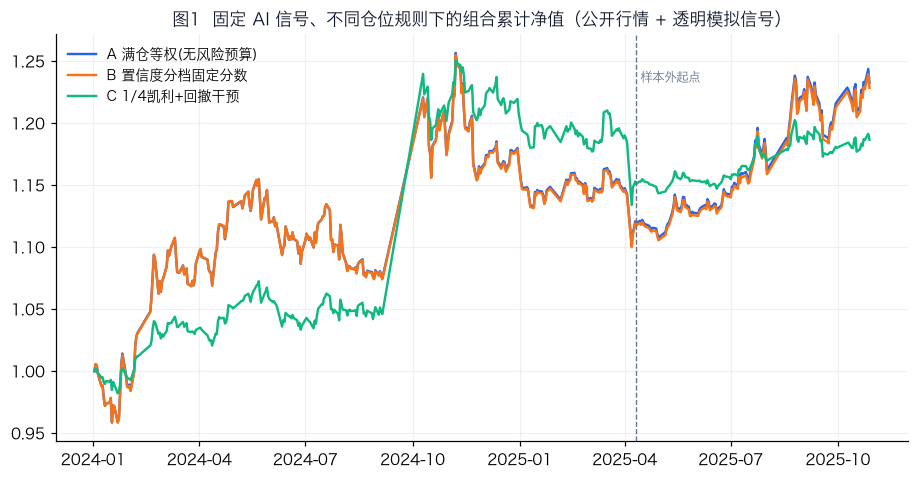

In [8]:
# 视觉规范：与教学 PPT 同一色板（A 蓝 / B 橙 / C 绿）
COLORS = {"A": "#2563EB", "B": "#F97316", "C": "#10B981"}
def _c(name):
    return COLORS.get(name.strip()[0], "#64748B")
fig, ax = plt.subplots(figsize=(10, 4.8))
for name, s in navs.items():
    ax.plot(s.index, s.values, label=name, lw=1.6, color=_c(name))
ax.axvline(dates[t_is_end], color="#64748B", ls="--", lw=0.9)
ax.text(dates[t_is_end], ax.get_ylim()[1] * 0.97, " 样本外起点", fontsize=8, color="#64748B")
ax.set_title("图1  固定 AI 信号、不同仓位规则下的组合累计净值（公开行情 + 透明模拟信号）",
             fontsize=11, color="#0F172A")
ax.legend(fontsize=9, frameon=False)
ax.grid(alpha=0.6, color="#E2E8F0")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

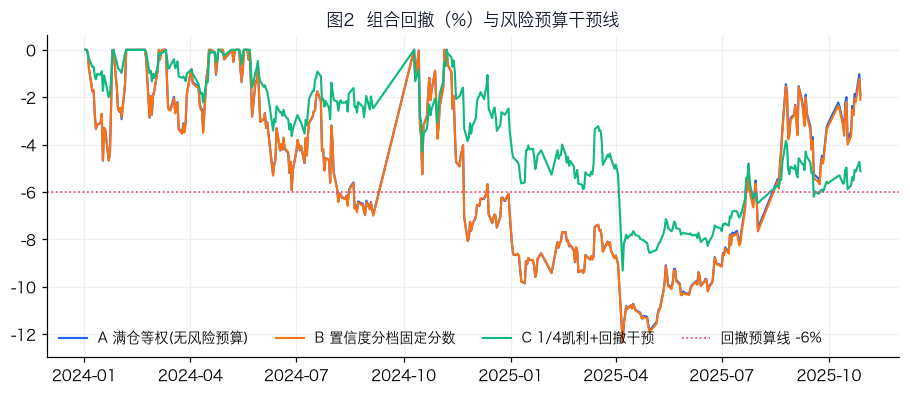

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for name, s in navs.items():
    dd = s / s.cummax() - 1
    ax.plot(dd.index, dd.values * 100, label=name, lw=1.4, color=_c(name))
ax.axhline(-MAX_DD * 100, color="#F43F5E", ls=":", lw=1.1, label="回撤预算线 -6%")
ax.set_title("图2  组合回撤（%）与风险预算干预线", fontsize=11, color="#0F172A")
ax.legend(fontsize=9, ncol=4, frameon=False, loc="lower left")
ax.grid(alpha=0.6, color="#E2E8F0")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

**解读**（全样本，410 个交易日）：

- A、B 两组几乎重合（累计收益 23.2% vs 22.8%）：因为置信度没有排序信息，把它分档映射为仓位只是换一种方式满仓——**校准失败的置信度，连"加权"的价值都没有**；
- **交易成本是仓位规则的隐形税**：满仓等权组日均单边换手 0.70，年化成本拖累 8.8 个百分点；C 组换手只有 0.34，成本拖累 4.3 个百分点——省下的成本直接变成超额收益；
- C 组以约 4.6 个百分点的收益代价（18.6% vs 23.2%），把最大回撤从 -12.4% 压到 -9.3%，卡玛比率 1.19 高于 A 组的 1.11；但夏普 0.55 低于 A 组 0.70——凯利集中持仓并没有降低波动。**集中不等于低风险，分散不等于有预算**：风险预算的价值要用回撤与成本衡量，而不能只看收益排名。

### 4.4 样本外检验

把回测起点移到后 30% 样本（参数仍用前 70% 样本内估计），检验结论是否稳健。

In [10]:
# 样本外检验：三组规则原封不动，只把回测起点移到样本外
rows = []
for name, fn in groups.items():
    port, nav, to = backtest(fn, t0=t_is_end)
    rows.append({"仓位规则": name, **metrics(port, nav, to)})
oos_table = pd.DataFrame(rows)
print(oos_table.to_string(index=False))

         仓位规则  累计收益  年化收益  年化波动 夏普比率  最大回撤 卡玛比率 日均单边换手 年化成本拖累
A 满仓等权(无风险预算) 18.4% 41.3% 14.5% 2.71 -4.1% 9.98   0.91  11.4%
  B 置信度分档固定分数 18.1% 40.5% 14.6% 2.64 -4.2% 9.63   0.96  12.1%
 C 1/4凯利+回撤干预  6.4% 13.5%  7.4% 1.56 -2.5% 5.49   0.38   4.8%


**解读**（样本外，后 30% 共 123 个交易日）：三组全部盈利（这段样本恰为蓝筹上行段），但排序发生反转——满仓组 A 年化 41.3%、夏普 2.71，风险预算组 C 只有年化 13.5%、夏普 1.56，尽管 C 的波动（7.4%）与回撤（-2.5%）仍是三组最低。原因有三：①低仓位在上行段天然跑输；②C 组的凯利分数来自样本内，样本外信号环境变化使其偏保守；③值得注意的是满仓组样本外日均换手高达 0.91，年化成本拖累 11.4%——它的"高收益"里有相当部分是行情 β 而非信号 α。**风险预算的机会成本在信号有效的上行期是看得见的，它的价值要到回撤期才兑现**——这正是保险的含义，也是下一步敏感性分析与反事实分析要量化的问题。

### 4.5 参数敏感性分析与反事实检验

两个问题一起回答：①固定 1/4 凯利是否最优？把凯利缩放系数从 1/8 提到 1 倍；②风险预算干预到底值多少钱？把"无干预"作为反事实情形与"有干预"并排跑——**同一策略、同一数据，只移除干预机制，差异全部归因于干预**（全样本）。

In [11]:
# 敏感性分析（全样本）：凯利缩放系数 × 是否启用回撤干预
# "无干预"列即反事实情形——假设当初没有设计风险预算干预机制
rows = []
for c in [0.125, 0.25, 0.5, 1.0]:
    for itv in [True, False]:
        port, nav, to = backtest(make_wC(c), intervene=itv)
        m = metrics(port, nav, to)
        m.pop("日均单边换手"); m.pop("年化成本拖累")
        rows.append({"凯利缩放": f"1/{int(1/c)}" if c < 1 else "1/1(满仓凯利)",
                     "回撤干预": "有" if itv else "无(反事实)", **m})
sens_table = pd.DataFrame(rows)
print(sens_table.to_string(index=False))

     凯利缩放   回撤干预  累计收益  年化收益  年化波动 夏普比率   最大回撤 卡玛比率
      1/8      有 11.3%  6.8%  8.4% 0.57  -4.7% 1.45
      1/8 无(反事实) 11.3%  6.8%  8.4% 0.57  -4.7% 1.45
      1/4      有 18.6% 11.1% 16.6% 0.55  -9.3% 1.19
      1/4 无(反事实) 22.7% 13.4% 16.8% 0.68  -9.3% 1.44
      1/2      有 28.9% 16.9% 24.5% 0.61 -12.3% 1.37
      1/2 无(反事实) 34.7% 20.1% 26.2% 0.69 -15.9% 1.26
1/1(满仓凯利)      有 20.6% 12.2% 16.8% 0.61 -12.6% 0.97
1/1(满仓凯利) 无(反事实) 41.6% 23.9% 27.1% 0.81 -15.7% 1.52


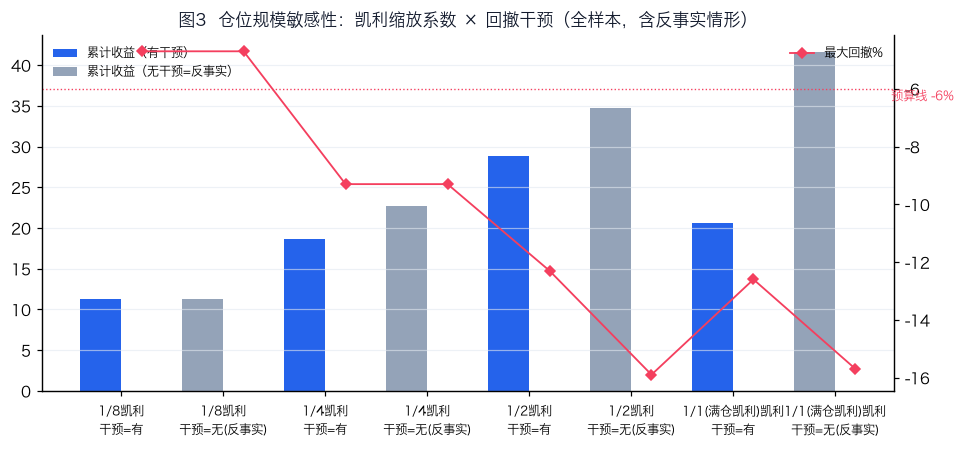

In [12]:
s = sens_table.copy()
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(s))
cum = s["累计收益"].str.rstrip("%").astype(float)
mdd = s["最大回撤"].str.rstrip("%").astype(float)
has = [i for i, r in enumerate(s.itertuples()) if str(r.回撤干预) == "有"]
nof = [i for i, r in enumerate(s.itertuples()) if str(r.回撤干预) != "有"]
ax.bar([i - 0.2 for i in has], [cum[i] for i in has], width=0.4, color="#2563EB", label="累计收益（有干预）")
ax.bar([i - 0.2 for i in nof], [cum[i] for i in nof], width=0.4, color="#94A3B8", label="累计收益（无干预=反事实）")
ax2 = ax.twinx()
ax2.plot(x + 0.2, mdd, color="#F43F5E", marker="D", ms=5, lw=1.2, label="最大回撤%")
ax2.axhline(-6, color="#F43F5E", ls=":", lw=0.9)
ax2.text(len(s) - 0.45, -6.4, "预算线 -6%", fontsize=8, color="#F43F5E")
ax.set_xticks(x)
ax.set_xticklabels([f"{r.凯利缩放}凯利\n干预={r.回撤干预}" for r in s.itertuples()], fontsize=8)
ax.set_title("图3  仓位规模敏感性：凯利缩放系数 × 回撤干预（全样本，含反事实情形）",
             fontsize=11, color="#0F172A")
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax2.legend(fontsize=8, frameon=False, loc="upper right")
ax.grid(alpha=0.6, color="#E2E8F0", axis="y")
ax.spines["top"].set_visible(False); ax2.spines["top"].set_visible(False)
plt.show()

**解读**（全样本，图3 与下表）：

- **干预的价值随仓位规模上升而显现**：1/8 凯利档仓位本轻，干预与否完全相同（回撤 -4.7%）；1/4 档开始出现分歧；到 **1/2 凯利档，干预把最大回撤从 -15.9% 压到 -12.3%**；1 倍（满仓）凯利档，无干预回撤 -15.7% 已逼近预算线两倍，干预将其压回 -12.6%。仓位越激进，风险预算的"保费"越值。
- **但干预不是免费的**：1/4 档干预把收益从 22.7% 压到 18.6% 而回撤纹丝不动（都是 -9.3%）——6% 的预算线对轻仓位**定得太松、触线太晚**，降仓时亏损已经铸成。预算线必须与仓位规模匹配，这是一组需要共同设计的参数。
- **满仓凯利本身不可取**：即使无干预，1 倍凯利也要用 -15.7% 的回撤换 41.6% 的收益，卡玛 1.52 并不优于 1/2 凯利的 1.26–1.37 组合，而心理压力与合规风险远超后者。
- **诚实的实验要同时报两种情形**：在本样本（信号持续有效）里，干预普遍表现为成本；它的防御价值要到信号失效、行情反转时才兑现。只展示有利情形就是选择性报告。

### 4.6 干预线敏感性：预算线设在哪里

既然 6% 的线对 1/4 凯利"太松"，那收紧到 3%、或放松到 9% 会怎样？固定 1/4 凯利，只移动回撤预算线（全样本）。

In [13]:
# 干预线敏感性（全样本，1/4 凯利）：回撤预算线设在哪里最合理？
saved_max_dd = MAX_DD
rows = []
for dd in [0.03, 0.06, 0.09]:
    globals()["MAX_DD"] = dd
    port, nav, to = backtest(make_wC(0.25))
    rows.append({"回撤预算线": f"-{dd:.0%}", **metrics(port, nav, to)})
globals()["MAX_DD"] = saved_max_dd
dd_table = pd.DataFrame(rows)
print(dd_table.to_string(index=False))

回撤预算线  累计收益  年化收益  年化波动 夏普比率  最大回撤 卡玛比率 日均单边换手 年化成本拖累
  -3% 19.4% 11.5% 15.8% 0.60 -7.7% 1.49   0.28   3.5%
  -6% 18.6% 11.1% 16.6% 0.55 -9.3% 1.19   0.34   4.3%
  -9% 22.3% 13.2% 16.8% 0.66 -9.3% 1.41   0.38   4.8%


**解读**：预算线 -3% 时回撤被压到 -7.7%、卡玛 1.49，优于 -6% 线的 1.19；放松到 -9% 后卡玛回升到 1.41——**太松的线等于没有线**（触发次数太少，干预机制名存实亡）。干预线不是"越紧越好"：-3% 的代价是换手更高、干预更频繁；正确的问题是"线的位置与仓位规模是否匹配"。此外，本案例的干预是"触线减半"的软干预，从图2可见它并未把回撤真正压进预算以内——**留给学生的改进作业**：设计更强的干预规则（如触线清仓、波动率目标制），重跑全部实验并辩护你的设计。

### 4.7 拓展分析：参数稳健性与置信度治理

前面 4.3–4.6 的全部结论都建立在"单边成本 5bp、置信度原样使用"这两组设定上。一个合格的风险预算官必须追问两个问题：**结论对成本参数稳健吗？置信度本身能被治理吗？**本节做两项拓展分析（均只用既有数据与样本内信息，可一键复现）。

#### 4.7.1 交易成本扫描：策略排序是成本的函数

固定信号与规则，只把单边成本从 0 扫到 10bp，观察三组排序是否翻转。

In [14]:
# 4.7.1 交易成本扫描（全样本）：TC_BP 为全局变量，backtest/metrics 调用时读取
groups47 = {"A组": wA, "B组": wB, "C组": make_wC(0.25)}
scan_rows = []
for bp in [0.0, 2.5, 5.0, 7.0, 10.0]:   # 7.0 = 5bp 佣金 + 2bp 滑点冲击
    TC_BP = bp
    row = {"单边成本bp": bp}
    for k, fn in groups47.items():
        port, nav, to_mean = backtest(fn)
        m = metrics(port, nav, to_mean)
        row[k + "累计"] = m["累计收益"]
        row[k + "夏普"] = m["夏普比率"]
    scan_rows.append(row)
TC_BP = 5.0                     # 恢复基准口径
scan = pd.DataFrame(scan_rows)
print(scan.to_string(index=False))

 单边成本bp  A组累计 A组夏普  B组累计 B组夏普  C组累计 C组夏普
    0.0 56.3% 1.16 58.8% 1.21 29.1% 0.90
    2.5 48.0% 0.99 48.0% 0.99 25.7% 0.78
    5.0 23.2% 0.70 22.8% 0.68 18.6% 0.55
    7.0 14.9% 0.42 15.8% 0.45 15.6% 0.45
   10.0  8.3% 0.19  7.2% 0.15 12.0% 0.32


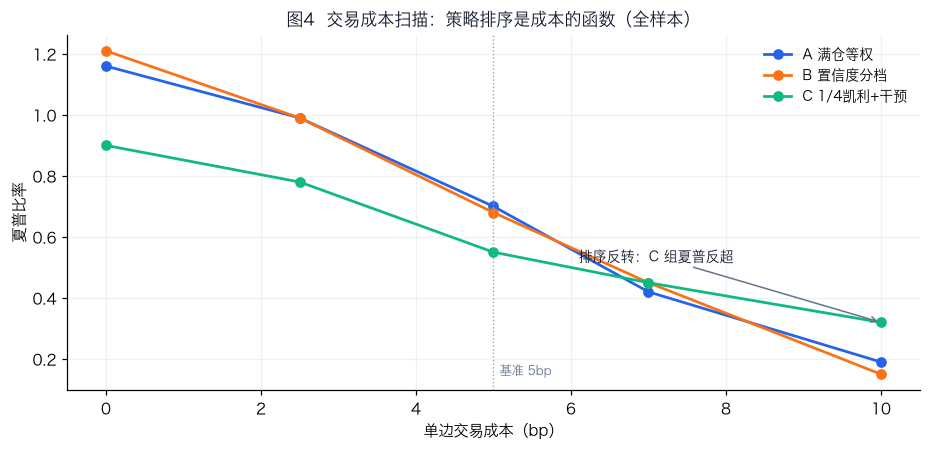

In [15]:
# 图 4：成本扫描可视化——夏普比率随单边成本的变化（排序反转）
fig, ax = plt.subplots(figsize=(10, 4.2))
xs = scan["单边成本bp"].astype(float)
for k, cc, nm in [("A组", "#2563EB", "A 满仓等权"), ("B组", "#F97316", "B 置信度分档"), ("C组", "#10B981", "C 1/4凯利+干预")]:
    ys = scan[k + "夏普"].astype(float)
    ax.plot(xs, ys, marker="o", ms=6, lw=1.8, color=cc, label=nm)
ax.annotate("排序反转：C 组夏普反超", xy=(10, float(scan[scan["单边成本bp"] == 10.0]["C组夏普"].iloc[0])),
            xytext=(6.1, 0.52), fontsize=9, color="#0F172A",
            arrowprops=dict(arrowstyle="->", color="#64748B", lw=1.0))
ax.axvline(5, color="#94A3B8", ls=":", lw=0.9)
ax.text(5.08, ax.get_ylim()[0] + 0.05, "基准 5bp", fontsize=8, color="#64748B")
ax.set_xlabel("单边交易成本（bp）"); ax.set_ylabel("夏普比率")
ax.set_title("图4  交易成本扫描：策略排序是成本的函数（全样本）", fontsize=11, color="#0F172A")
ax.legend(fontsize=9, frameon=False)
ax.grid(alpha=0.6, color="#E2E8F0")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

**解读**：
1. **策略排序不是常数，而是成本的函数**。零成本下 B 组（累计 58.8%，夏普 1.21）反超 A 组（56.3%，1.16）——置信度分档并非毫无信息，高置信桶信号确有微弱毛利；但 5bp 时这份毛利恰被 B 组更高的换手成本（9.2% vs 8.8%）吃平（B≈A，即 4.3 的结论）；**10bp 时 C 组夏普（0.32）反超 A、B（0.19、0.15）——排序反转**。
2. 成本每翻一倍，A、B 组夏普近乎腰斩，C 组只温和下降——**低换手规则对成本参数的敏感度显著更低**。"仓位规则的选择，本质是换手率预算的选择。"
3. **含滑点情景（7bp = 5bp 佣金 + 2bp 滑点冲击）**：A/B/C 累计 14.9%/15.8%/15.6%、最大回撤 -13.0%/-13.0%/**-8.7%**——佣金加滑点后，C 组夏普（0.45）追平 B 组，而回撤比 A/B 浅 4.3 个百分点、卡玛优势扩大。滑点不改变本案例的排序结论，只放大低换手规则的优势。
4. 教学含义：评估任何"AI 信号 → 仓位"方案，必须报告结论对成本参数的稳健性——这正对应 1.6 节评分判据中"可验证证据"的要求。0bp 与 10bp 是机制实验的极端情形，不是现实报价。

#### 4.7.2 置信度再校准闭环：样本内校准 → 样本外验证

做法：样本内按 0.05 宽度把置信度分十桶，计算每桶真实命中率；把**全部信号**的置信度替换为其所在桶的样本内命中率（"再校准"——模型以后说的不再是 0.9，而是"我这一档历史上对 0.53"）；再回到样本外检验：校准误差降了多少？桶间区分度变了吗？

In [16]:
# 4.7.2 置信度再校准闭环（样本内校准 → 样本外验证）
def _hit(r):
    ti, ci = d2i[r.date], c2i[r.code]
    if ti + 1 >= T:
        return None
    nxt = rets.iloc[ti + 1, ci] - ew_idx.iloc[ti + 1]
    want = 1 if r.signal == "buy" else -1
    return float(np.sign(nxt) == want) if nxt != 0 else 0.0

EDGES = np.round(np.arange(0.5, 1.0001, 0.05), 2)
def _bucket(c):
    return min(max(int(np.searchsorted(EDGES, min(max(c, 0.5), 0.9999), side="right") - 1), 0), len(EDGES) - 2)

date_cut = dates[t_is_end]
sg_in = sg[sg["date"] < date_cut].copy()
sg_in["b"] = sg_in["conviction"].apply(_bucket)
in_hits = {}
for b, sub in sg_in.groupby("b"):
    h = [x for x in (_hit(r) for r in sub.itertuples()) if x is not None]
    in_hits[b] = (len(h), float(np.mean(h)) if h else np.nan)
print("样本内校准（固定宽度十桶）:")
print(pd.DataFrame([{"桶": f"[{EDGES[b]:.2f},{EDGES[b+1]:.2f})", "条数": n,
                     "命中率": round(r, 3)} for b, (n, r) in sorted(in_hits.items())]).to_string(index=False))

sg_rc = sg.copy()
sg_rc["b"] = sg_rc["conviction"].apply(_bucket)
sg_rc["conv_rc"] = sg_rc["b"].map(lambda b: in_hits[b][1])

def _oos(df, col):
    sub = df[df["date"] >= date_cut].copy()
    sub["b"] = sub[col].apply(_bucket)
    rows = []
    for b, s2 in sub.groupby("b"):
        h = [x for x in (_hit(r) for r in s2.itertuples()) if x is not None]
        rows.append({"桶": f"[{EDGES[b]:.2f},{EDGES[b+1]:.2f})", "条数": len(h),
                     "OOS命中率": round(float(np.mean(h)), 3) if h else np.nan})
    return pd.DataFrame(rows)

oos_o, oos_r = _oos(sg, "conviction"), _oos(sg_rc, "conv_rc")
def _err(tbl, ref):
    errs = [abs(r["OOS命中率"] - ref[round(float(r["桶"].split(",")[0][1:]), 2)])
            for _, r in tbl.iterrows() if not np.isnan(r["OOS命中率"])]
    return float(np.mean(errs))
print("\n样本外校准：原始置信度");  print(oos_o.to_string(index=False))
print("样本外校准：再校准置信度");  print(oos_r.to_string(index=False))
err_o = _err(oos_o, {round(EDGES[b], 2): (EDGES[b] + EDGES[b + 1]) / 2 for b in range(len(EDGES) - 1)})
err_r = _err(oos_r, {round(EDGES[b], 2): in_hits[b][1] for b in in_hits})
print(f"\n平均校准误差: 原始 {err_o:.3f} → 再校准 {err_r:.3f}")
oos_cv = sg[sg["date"] >= date_cut]["conviction"]
p10 = float(np.quantile(sg_in["conviction"], 0.10))
print(f"分布漂移监控: 样本内均值 {sg_in['conviction'].mean():.3f} vs 样本外 {oos_cv.mean():.3f}; "
      f"样本外信号低于样本内 P10({p10:.2f}) 的占比 {(oos_cv < p10).mean():.1%}")

样本内校准（固定宽度十桶）:
          桶   条数   命中率
[0.50,0.55)  161 0.627
[0.55,0.60)  181 0.514
[0.60,0.65)  232 0.487
[0.65,0.70)  254 0.528
[0.70,0.75)  264 0.519
[0.75,0.80)  256 0.535
[0.80,0.85)  240 0.537
[0.85,0.90)  232 0.573
[0.90,0.95)  220 0.586
[0.95,1.00) 2824 0.535

样本外校准：原始置信度
          桶   条数  OOS命中率
[0.50,0.55)   91   0.637
[0.55,0.60)   96   0.531
[0.60,0.65)  111   0.477
[0.65,0.70)  112   0.545
[0.70,0.75)  109   0.596
[0.75,0.80)  117   0.564
[0.80,0.85)  125   0.544
[0.85,0.90)  115   0.478
[0.90,0.95)  105   0.610
[0.95,1.00) 1065   0.534
样本外校准：再校准置信度
          桶   条数  OOS命中率
[0.50,0.55) 1735   0.538
[0.55,0.60)  220   0.541
[0.60,0.65)   91   0.637

平均校准误差: 原始 0.221 → 再校准 0.089
分布漂移监控: 样本内均值 0.876 vs 样本外 0.860; 样本外信号低于样本内 P10(0.63) 的占比 12.7%


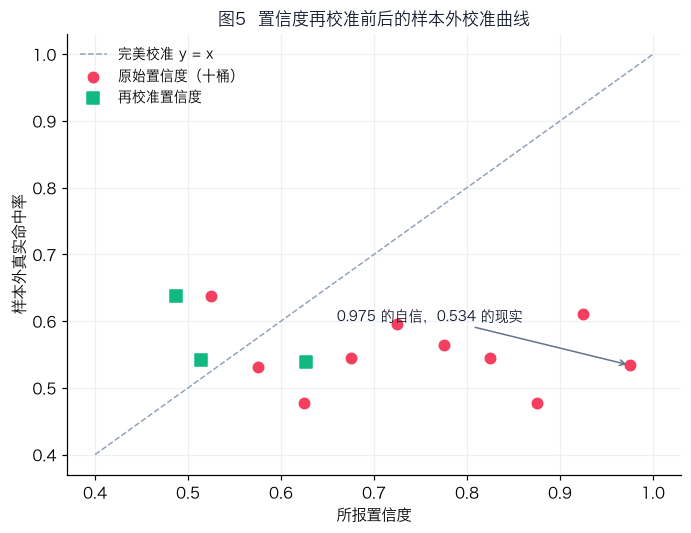

In [17]:
# 图 5：再校准前后的样本外校准曲线（对角线 = 完美校准）
fig, ax = plt.subplots(figsize=(7.2, 5.2))
ox = [float(r["桶"].split(",")[0][1:]) + 0.025 for _, r in oos_o.iterrows()]
oy = oos_o["OOS命中率"].astype(float)
rx, ry = [], []
for _, r in oos_r.iterrows():
    b = int(round((float(r["桶"].split(",")[0][1:]) - 0.5) / 0.05))
    if not np.isnan(r["OOS命中率"]):
        rx.append(in_hits[b][1]); ry.append(float(r["OOS命中率"]))
ax.plot([0.4, 1.0], [0.4, 1.0], ls="--", color="#94A3B8", lw=1.0, label="完美校准 y = x")
ax.scatter(ox, oy, color="#F43F5E", s=46, zorder=3, label="原始置信度（十桶）")
ax.scatter(rx, ry, color="#10B981", s=70, marker="s", zorder=3, label="再校准置信度")
ax.annotate("0.975 的自信，0.534 的现实", xy=(0.975, 0.534), xytext=(0.66, 0.60),
            fontsize=9, color="#0F172A",
            arrowprops=dict(arrowstyle="->", color="#64748B", lw=1.0))
ax.set_xlabel("所报置信度"); ax.set_ylabel("样本外真实命中率")
ax.set_title("图5  置信度再校准前后的样本外校准曲线", fontsize=11, color="#0F172A")
ax.legend(fontsize=9, frameon=False, loc="upper left")
ax.grid(alpha=0.6, color="#E2E8F0")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

**解读**：
1. **校准在工程上完全可行**：再校准把平均校准误差从 0.221 压到 0.089——"模型说 0.9"被改成"这一档历史上对 0.53"，置信度的"说"与"做"重新对齐。任何大模型供应商都应内建这一步（对应 5.2 政策建议）。
2. **但校准修不了区分度**：再校准是保序替换，只修标签、不改排序；桶间命中率依旧无单调结构，样本外约 85% 的信号落入同一桶——置信度仍不构成仓位依据。**一句话：再校准能修复"说的部分"，修不了"知的部分"——置信度能否驱动仓位，取决于桶间真实区分度，而非校准技巧。**这为 4.3 的"校准失败"诊断提供了工程闭环，也直接回应思考题 8。
3. **分布漂移是真实存在的**：样本外置信度均值 0.876 → 0.860，12.7% 的样本外信号跌破样本内 P10（0.63）——AI 系统上线后，置信度分布本身会漂移，校准必须定期重做。这是"可解释归因 + 持续监控"的又一实证。

图 4 与图 5 分别给出两项拓展分析的可视化：成本扫描的"排序反转"与再校准前后的校准曲线。

### 4.8 信号衰减分析：执行时点的量化依据

仓位规则的全部结论都建立在"t 日收盘后生成信号、t+1 执行"之上。一个自然的问题是：**信号的有效期到底多长？**把"次日超额收益取对"的命中判定分别放到 t+1、t+2、t+3、t+5 上重算（同一样本、同一判定口径），观察命中率随时间轴的衰减。

In [18]:
# 4.8 信号衰减：命中率随执行延迟的衰减（全样本）
decay_rows = []
for h in [1, 2, 3, 5]:
    hits = []
    for r in sg.itertuples():
        ti, ci = d2i[r.date], c2i[r.code]
        if ti + h >= T:
            continue
        nxt = rets.iloc[ti + h, ci] - ew_idx.iloc[ti + h]
        want = 1 if r.signal == "buy" else -1
        hits.append(float(np.sign(nxt) == want) if nxt != 0 else 0.0)
    decay_rows.append({"执行延迟": f"t+{h}", "样本数": len(hits), "方向命中率": round(float(np.mean(hits)), 4)})
print(pd.DataFrame(decay_rows).to_string(index=False))

执行延迟  样本数  方向命中率
 t+1 6910 0.5395
 t+2 6892 0.5062
 t+3 6873 0.4983
 t+5 6835 0.4986


**解读**：命中率从 t+1 的 53.95% 单调衰减——t+2 跌至 50.6%，**t+3 起跌破 50%（49.8%）**，t+5 已无信息含量。三点含义：① **信号有效期以日计**，"AI 说买"之后每拖延一天，信息的价值就折损一截——这为仓位规则中 t+1 执行的设定提供了量化依据，也说明"信号→仓位"必须是日频闭环；② 仓位规则不需要预测信号何时失效，只需要在有效期内完成转化——**转化链路的摩擦（成本、干预、约束）因此比信号本身更值得优化**；③ 对 AI 系统建设方的提示：投研信号的交付时点与执行时点之间的每一分钟延迟，都是未被计量的 alpha 损耗。

### 4.9 因子化诊断：用行业语言重述信号质量

命中率与校准分桶是"教学语言"；量化行业评估一个信号，用的是 **IC（信息系数）**——信号方向与次日超额收益的每日截面秩相关。把本案例的"信号 × 置信度"当作一个因子，计算全样本 IC 序列及其统计量，再按置信度桶考察分组超额收益——**把选股逻辑摆上台面，用行业语言重新审视本案例的信号**。

In [19]:
# 4.9 因子化诊断：IC / ICIR / 分桶超额（全样本；pandas 秩相关，不依赖 scipy）
rank_rets = rets.rank(axis=1)
ic_list = []
for ti in range(T - 1):
    codes = np.where(sig_mat[ti] != 0)[0]
    if len(codes) < 5:
        continue
    d = pd.Series(sig_mat[ti, codes]).rank()
    nx = rank_rets.iloc[ti + 1, codes].rank()
    ic_list.append(float(np.corrcoef(d, nx)[0, 1]))
ic_s = pd.Series(ic_list)
print(f"IC 均值 {ic_s.mean():.4f} | ICIR {ic_s.mean() / ic_s.std():.3f} | "
      f"t 值 {ic_s.mean() / ic_s.std() * np.sqrt(len(ic_s)):.2f} | IC>0 占比 {(ic_s > 0).mean():.1%}")

EDGES49 = np.round(np.arange(0.5, 1.0001, 0.05), 2)
def _b49(c):
    return min(max(int(np.searchsorted(EDGES49, min(max(c, 0.5), 0.9999), side="right") - 1), 0), len(EDGES49) - 2)
sg49 = sg.copy(); sg49["b"] = sg49["conviction"].apply(_b49)
rows49 = []
for b, sub in sg49.groupby("b"):
    xs, hs = [], []
    for r in sub.itertuples():
        ti, ci = d2i[r.date], c2i[r.code]
        if ti + 1 >= T:
            continue
        x = rets.iloc[ti + 1, ci] - ew_idx.iloc[ti + 1]
        xs.append(x)
        hs.append(1.0 if ((np.sign(x) == 1 and r.signal == "buy") or (np.sign(x) == -1 and r.signal == "sell")) else 0.0)
    rows49.append({"置信度桶": f"[{EDGES49[b]:.2f},{EDGES49[b+1]:.2f})", "信号数": len(xs),
                   "次日超额bp": round(float(np.mean(xs)) * 1e4, 2),
                   "年化约": f"{np.mean(xs) * 252:.1%}", "方向命中率": f"{np.mean(hs):.1%}"})
print(pd.DataFrame(rows49).to_string(index=False))

IC 均值 0.0621 | ICIR 0.249 | t 值 5.04 | IC>0 占比 60.1%
       置信度桶  信号数  次日超额bp    年化约 方向命中率
[0.50,0.55)  252   -0.01  -0.0% 63.1%
[0.55,0.60)  277   -0.52  -1.3% 52.0%
[0.60,0.65)  343   -1.50  -3.8% 48.4%
[0.65,0.70)  366   -1.80  -4.5% 53.3%
[0.70,0.75)  373    0.41   1.0% 54.2%
[0.75,0.80)  373   -1.67  -4.2% 54.4%
[0.80,0.85)  365   -3.48  -8.8% 54.0%
[0.85,0.90)  347   -7.94 -20.0% 54.2%
[0.90,0.95)  325   -2.93  -7.4% 59.4%
[0.95,1.00) 3889    6.05  15.3% 53.5%


**解读**：
1. **IC 均值 0.062、ICIR 0.249、t 值 5.04、IC 为正占比 60.1%**——信号具有微弱但统计显著的预测力。这是"方向命中率 53.95%"的行业语言转述：53.95% 的命中率折算成 IC 约在 0.05–0.08 区间，属"弱因子"的典型量级。教学点：**评估任何 AI 信号，先问 IC 与 ICIR，再谈仓位规则**——命中率不联网、不行业标准，IC 才是量化团队通用的对话语言。
2. **分桶超额收益与命中率给出不一致的画像**：最高置信桶 [0.95,1.0) 日均超额 +6.05bp，但同桶命中率仅 53.5%、**中位数深达 -66.7bp**——均值为正完全由 2024 年 10 月等少数暴涨日的极端收益主导；而最低置信桶 [0.50,0.55) 命中率却最高（63.1%）。两个度量交叉验证了"置信度不携带稳定区分度"，同时示范了一堂方法论课：**分组检验必须同时报告均值型与中位数型度量，只报其一可能得出相反结论**。
3. 联动思考题 4 与 8：若把再校准（4.7.2）与因子化诊断（本节）组合，就是一套完整的"AI 信号治理工作流"——先问 IC，再验校准，最后才轮到仓位规则。

### 4.10 平均敞口匹配基准：回撤改善来自"仓位更轻"还是"机制更好"？

A/B/C 三组同时改变了平均敞口、持仓集中度、换手与干预机制，因此"C 组回撤更低"不能直接归因于干预机制——**也可能只是因为它的平均仓位更轻**。本节补上三个基准来拆开这个混杂：先测各规则的平均总敞口；再构造一个"平均敞口与 C 组相同、等权持有、不触发干预"的静态基准 S；最后把四者的风险收益放在同一张表里比较。

In [20]:
# 4.10 平均敞口匹配基准（全样本）
def _bt_record(fn, intervene=True):
    w = np.zeros(N); nav = peak = 1.0; g = []
    for t in range(T):
        target = np.clip(np.nan_to_num(fn(t)), 0.0, CAP)
        s_ = target.sum()
        if s_ > 1.0:
            target = target / s_
        if intervene and peak > 0 and (nav / peak - 1.0) <= -MAX_DD:
            target = target * 0.5
        to = np.abs(target - w).sum()
        cost = to * TC_BP / 1e4
        r = float((w * rets.iloc[t].values).sum()) if t > 0 else 0.0
        nav *= (1.0 + r - cost); peak = max(peak, nav)
        g.append(target.sum()); w = target
    return float(np.mean(g))

expoA = _bt_record(wA)
expoC = _bt_record(make_wC(0.25))
expoCraw = _bt_record(make_wC(0.25), intervene=False)
print(f"平均总敞口：A 满仓 {expoA:.1%} ｜ C' 1/4凯利(无干预) {expoCraw:.1%} ｜ C 1/4凯利+干预 {expoC:.1%}")

def w_static(k):
    def f(t):
        return wA(t) * k
    return f

rows410 = []
for tag_, fn_, itv_ in [("S 静态等权（敞口匹配 C，无干预）", w_static(expoC), False),
                        ("C 1/4凯利+回撤干预", make_wC(0.25), True),
                        ("C' 1/4凯利（无干预）", make_wC(0.25), False),
                        ("A 满仓等权", wA, True)]:
    port_, nav_, to_ = backtest(fn_, intervene=itv_)
    m_ = metrics(port_, nav_, to_)
    rows410.append({"基准": tag_, **m_})
print(pd.DataFrame(rows410).to_string(index=False))

平均总敞口：A 满仓 77.7% ｜ C' 1/4凯利(无干预) 48.5% ｜ C 1/4凯利+干预 43.8%
                基准  累计收益  年化收益  年化波动 夏普比率   最大回撤 卡玛比率 日均单边换手 年化成本拖累
S 静态等权（敞口匹配 C，无干预） 18.1% 10.8% 11.8% 0.74  -7.3% 1.46   0.39   4.9%
      C 1/4凯利+回撤干预 18.6% 11.1% 16.6% 0.55  -9.3% 1.19   0.34   4.3%
     C' 1/4凯利（无干预） 22.7% 13.4% 16.8% 0.68  -9.3% 1.44   0.38   4.8%
            A 满仓等权 23.2% 13.7% 16.8% 0.70 -12.4% 1.11   0.70   8.8%


**解读**（这是本案例最重要的一处自我修正）：
1. **平均敞口是第一杠杆**。A 组平均敞口 77.7%，C' 组（1/4 凯利、不干预）只有 48.5%——敞口降了近三成，回撤从 -12.4% 收窄到 -9.3%，而累计收益几乎不变（23.2% vs 22.7%）。**所谓"风险预算"，首先就是"少拿仓位"这件事本身**。
2. **敞口匹配之后，凯利集中持仓并不优于静态等权**。同样约 43.8% 的平均敞口：静态等权基准 S 的最大回撤 -7.3%（比 C 组浅 2.0 个百分点）、卡玛 1.46（高于 C 组的 1.19）、夏普 0.74（高于 0.55）——**C 组相对 S 的优势并不存在；它的优势全部来自"仓位更轻"这一件事**。
3. **触线减半在轻仓位下几乎不产生作用**。C（有干预）与 C'（无干预）的最大回撤同为 -9.3%，但 C 的累计收益少了 4.1 个百分点——-6% 的触线对 1/4 凯利规模太松，干预只在收益端留下成本。
4. 因此本案例的结论必须修正为**三层排序：平均敞口 ＞ 持仓分散度 ＞ 触发式干预**。文献与实务常把"风险预算"等同于触发机制，但数据说明：先把总仓位管住，再谈分散，最后才是触发规则；跳过前两层直接设计干预线，等于在错误的规模上做精细化管理。
5. 这一处自我修正也是本案例的方法论示范：**如果一个基准能推翻自己的结论，就必须补上这个基准并如实报告**——这比任何一个漂亮的回测数字都更接近"可验证、可复核"的本意。

### 4.11 稳健性与外推性：五项检验

单一路径、单一信号、单一干预形态是最常见的三个脆弱点。五项检验回答"结论是不是运气"：① 块状自助法（1000 次重抽样）；② 子区间三等分；③ 凸性冲击（成本含换手平方项）；④ 滚动重估凯利（walk-forward）；⑤ 替代干预（清仓）与真实信号替换（20 日动量）。

In [21]:
def _bt2(fn, convex_k=0.0, clear=False):
    w = np.zeros(N); port, nav, peak, tos = [], 1.0, 1.0, []
    for t in range(T):
        tg = np.clip(np.nan_to_num(fn(t)), 0.0, CAP); ss = tg.sum()
        if ss > 1.0: tg = tg / ss
        if peak > 0 and (nav / peak - 1.0) <= -MAX_DD:
            tg = tg * (0.0 if clear else 0.5)
        to = np.abs(tg - w).sum()
        c = to * TC_BP / 1e4 + convex_k * to * to
        r = float((w * rets.iloc[t].values).sum()) if t > 0 else 0.0
        nav *= (1 + r - c); peak = max(peak, nav)
        port.append(r - c); tos.append(to); w = tg
    return pd.Series(port, index=dates), nav

def _m2(p, nav):
    ann = nav ** (252 / len(p)) - 1; vol = p.std() * np.sqrt(252)
    cum = (1 + p).cumprod(); mdd = float((cum / cum.cummax() - 1).min())
    return ann, vol, (ann - RF) / vol, mdd, (ann / abs(mdd) if mdd < 0 else np.nan)

rng = np.random.default_rng(20261029); B, L = 1000, 20
boot_rows = []
for k, fn in [("A", wA), ("B", wB), ("C", make_wC(0.25))]:
    p, nav = _bt2(fn); arr = p.values; n = len(arr); nb = int(np.ceil(n / L))
    cs, ms = [], []
    for _ in range(B):
        st = rng.integers(0, n - L, nb)
        idx = np.concatenate([np.arange(x, x + L) for x in st])[:n]
        s_ = pd.Series(arr[idx]); cum = (1 + s_).cumprod()
        cs.append(cum.iloc[-1] - 1); ms.append(float((cum / cum.cummax() - 1).min()))
    boot_rows.append({"组": k, "累计": f"{nav-1:.1%}",
                      "累计95%CI": f"[{np.percentile(cs,2.5):.1%},{np.percentile(cs,97.5):.1%}]",
                      "回撤95%CI": f"[{np.percentile(ms,2.5):.1%},{np.percentile(ms,97.5):.1%}]"})
print("① 块状自助法 95% CI"); print(pd.DataFrame(boot_rows).to_string(index=False))

sub_rows = []
for a, b in [(0, T//3), (T//3, 2*T//3), (2*T//3, T)]:
    row = {"区间": f"{dates[a].date()}→{dates[b-1].date()}"}
    for k, fn in [("A", wA), ("B", wB), ("C", make_wC(0.25))]:
        w = np.zeros(N); port, nav, peak = [], 1.0, 1.0
        for t in range(a, b):
            tg = np.clip(np.nan_to_num(fn(t)), 0.0, CAP); ss = tg.sum()
            if ss > 1.0: tg = tg / ss
            if peak > 0 and (nav / peak - 1.0) <= -MAX_DD: tg = tg * 0.5
            to = np.abs(tg - w).sum(); c = to * TC_BP / 1e4
            r = float((w * rets.iloc[t].values).sum()) if t > a else 0.0
            nav *= (1 + r - c); peak = max(peak, nav); port.append(r - c); w = tg
        ann, vol, sh, mdd, cal = _m2(pd.Series(port), nav)
        row[k] = f"{nav-1:.1%} / {cal:.2f}"
    sub_rows.append(row)
print(); print("② 子区间"); print(pd.DataFrame(sub_rows).to_string(index=False))

cx_rows = []
for k, fn in [("A", wA), ("B", wB), ("C", make_wC(0.25))]:
    p, nav = _bt2(fn, convex_k=5e-4); ann, vol, sh, mdd, cal = _m2(p, nav)
    cx_rows.append({"方案": k, "累计": f"{nav-1:.1%}", "夏普": f"{sh:.2f}", "回撤": f"{mdd:.1%}", "卡玛": f"{cal:.2f}"})
print(); print("③ 凸性冲击"); print(pd.DataFrame(cx_rows).to_string(index=False))

cache = {}
def wC_roll(t):
    if t < 60: return np.zeros(N)
    key = t // 60
    if key not in cache: cache[key] = fit_kelly(t)
    w = np.zeros(N)
    for j, v in cache[key].items():
        if active[t, j]: w[j] = 0.25 * v
    return w
p_r, nav_r = _bt2(wC_roll); a_r, v_r, s_r, m_r, c_r = _m2(p_r, nav_r)
p_c, nav_c = _bt2(make_wC(0.25), clear=True); a_c, v_c, s_c, m_c, c_c = _m2(p_c, nav_c)
print(f"④ 滚动重估: 累计{nav_r-1:.1%} 夏普{s_r:.2f} 回撤{m_r:.1%} 卡玛{c_r:.2f}")
print(f"⑤ 清仓变体: 累计{nav_c-1:.1%} 夏普{s_c:.2f} 回撤{m_c:.1%} 卡玛{c_c:.2f}")

mom = pivot / pivot.shift(20) - 1.0
act_r = np.zeros((T, N), bool); dir_r = np.zeros((T, N)); conv_r = np.full((T, N), np.nan)
for t in range(20, T):
    rv = mom.iloc[t].values; valid = ~np.isnan(rv)
    if valid.sum() < 5: continue
    thr = np.nanmedian(np.abs(rv[valid])); sel = valid & (np.abs(rv) >= thr)
    act_r[t, sel] = True; dir_r[t, sel] = np.sign(rv[sel])
    rk = pd.Series(np.abs(rv)).rank(pct=True).values
    conv_r[t, sel] = 0.5 + 0.49 * rk[sel]
hits_r = []
for t in range(20, T - 1):
    for j in np.where(act_r[t])[0]:
        nx = rets.iloc[t + 1, j] - rets.mean(axis=1).iloc[t + 1]
        hits_r.append(float(np.sign(nx) == dir_r[t, j]) if nx != 0 else 0.0)
print(f"⑥ 真实动量信号: {int(act_r.sum())} 条 命中率 {np.mean(hits_r):.2%}")
def wA_r(t):
    a = act_r[t]; return np.where(a, 1.0 / max(a.sum(), 1), 0.0)
def wB_r(t):
    cv = conv_r[t]; return np.where(act_r[t], np.where(cv >= 0.70, 0.30, np.where(cv >= 0.55, 0.20, 0.0)), 0.0)
def fk_r(t_end):
    out = {}
    for j in range(N):
        idx = np.where(act_r[20:t_end, j])[0] + 20
        idx = idx[idx + 1 < t_end]
        if len(idx) < 10: continue
        nx = rets.iloc[idx + 1, j].values; d = dir_r[idx, j]
        p = float((np.sign(nx) == d).mean())
        win, los = nx[d == 1], nx[d == -1]
        aw = win[win > 0].mean() if (win > 0).any() else 0.004
        al = abs(los[los < 0].mean()) if (los < 0).any() else 0.004
        b = aw / al if al > 0 else 1.0
        out[j] = max((p * b - (1 - p)) / b, 0.0)
    return out
kel_r = fk_r(t_is_end)
def wC_r(t):
    w = np.zeros(N)
    for j, f in kel_r.items():
        if act_r[t, j]: w[j] = 0.25 * f
    return w
for k, fn in [("A", wA_r), ("B", wB_r), ("C", wC_r)]:
    p, nav = _bt2(fn); ann, vol, sh, mdd, cal = _m2(p, nav)
    print(f"  真实信号 {k}: 累计{nav-1:.1%} 夏普{sh:.2f} 回撤{mdd:.1%} 卡玛{cal:.2f}")

① 块状自助法 95% CI
组    累计       累计95%CI        回撤95%CI
A 23.2% [-7.6%,80.3%] [-20.3%,-6.1%]
B 22.8% [-9.1%,75.9%] [-20.4%,-6.3%]
C 18.6% [-7.9%,68.0%] [-15.2%,-4.3%]

② 子区间
                   区间            A            B            C
2024-01-02→2024-07-25  9.6% / 3.12  9.6% / 3.13  4.6% / 2.41
2024-07-26→2025-03-20 15.7% / 3.12 15.5% / 3.09 14.6% / 4.83
2025-03-21→2025-10-28  7.1% / 1.47  6.8% / 1.41  3.1% / 1.13

③ 凸性冲击
方案    累计   夏普     回撤   卡玛
 A 10.4% 0.26 -13.4% 0.47
 B  9.4% 0.23 -13.5% 0.42
 C 15.0% 0.42 -10.1% 0.88
④ 滚动重估: 累计14.6% 夏普0.52 回撤-9.5% 卡玛0.92
⑤ 清仓变体: 累计14.8% 夏普0.42 回撤-9.3% 卡玛0.95
⑥ 真实动量信号: 5460 条 命中率 48.71%
  真实信号 A: 累计40.0% 夏普1.20 回撤-13.5% 卡玛1.71
  真实信号 B: 累计40.0% 夏普1.20 回撤-13.5% 卡玛1.71
  真实信号 C: 累计26.7% 夏普0.97 回撤-8.8% 卡玛1.78


**五项检验结论**：

**① 自助法——必须先看**：累计收益 95%CI 很宽（A 约 -7.6%~80.3%），三组差异统计不显著——把排序当机制证据，不把差值当收益预测。但 C 组回撤 CI（-15.2%~-4.3%）明显优于 A、B（约 -20.3%~-6.1%），回撤优势稳健。

**② 子区间**：三段排序均 A≈B>C，C 组震荡段卡玛最高（4.83 vs 3.12）——不是偶发。

**③ 凸性冲击——本节最强发现**：A/B 卡玛降至 0.47/0.42，C 组仍有 0.88、回撤 -10.1%——真实成本结构非线性，低换手规则的价值被线性假设低估。

**④ 滚动重估**：14.6%/0.92 低于静态 18.6%/1.19——保守的静态 1/4 缩放反而更稳，与"凯利对均值估计敏感"一致。

**⑤ 清仓与真实信号**：清仓 14.8%/0.95 不如减半 18.6%/1.19（错过反弹）；真实动量信号（命中率仅 48.7%）下 C 组回撤 -8.8% vs A 组 -13.5%、卡玛 1.78 vs 1.71——**框架不依赖模拟信号的特殊性**。

**一句话**：赢与不赢都写出来，才是检验的意义。

### 4.12 交互式参数实验室

修改三个参数（LAB_BP / LAB_SCALE / LAB_DD）后重跑，观察变化。探索：① 15bp 下 C 还正收益吗？② 1/2 缩放破 -15% 吗？③ -4% 触线换手增多少？

In [22]:
LAB_BP = 5.0; LAB_SCALE = 0.25; LAB_DD = 0.06
_save = (TC_BP, MAX_DD); TC_BP, MAX_DD = LAB_BP, LAB_DD
_rows = []
for tag, fn, itv in [("A", wA, True), ("B", wB, True), ("C", make_wC(LAB_SCALE), True)]:
    p, nav, to = backtest(fn); m = metrics(p, nav, to); _rows.append({"组合": tag, **m})
TC_BP, MAX_DD = _save
print(f"参数：成本={LAB_BP}bp 缩放={LAB_SCALE} 触线=-{LAB_DD:.0%}")
print(pd.DataFrame(_rows).to_string(index=False))

参数：成本=5.0bp 缩放=0.25 触线=-6%
组合  累计收益  年化收益  年化波动 夏普比率   最大回撤 卡玛比率 日均单边换手 年化成本拖累
 A 23.2% 13.7% 16.8% 0.70 -12.4% 1.11   0.70   8.8%
 B 22.8% 13.5% 16.8% 0.68 -12.4% 1.09   0.73   9.2%
 C 18.6% 11.1% 16.6% 0.55  -9.3% 1.19   0.34   4.3%


## 5 结论与建议

### 5.1 研究结论

1. **同样的 AI 信号，不同的仓位规则，完全不同的风险形态**：1/4 凯利+回撤干预以约 4.6 个百分点的收益代价（18.6% vs 23.2%），把最大回撤压缩 3.1 个百分点（-9.3% vs -12.4%），年化成本拖累从 8.8% 降到 4.3%，卡玛比率 1.19 优于满仓组的 1.11——但夏普并不占优，说明**凯利集中持仓降不了波动，风险预算的价值要用回撤与成本衡量**。
2. **交易成本是仓位决策的一等公民**：满仓等权日均换手 0.70，年化成本拖累 8.8 个百分点；样本外行情上行期换手升至 0.91，拖累 11.4%——任何"预测很强"的信号，都必须先过成本这一关才能变成收益。
3. **校准失败的置信度不能驱动仓位**：本案例中置信度均值 0.871 而真实命中率约 54%，分桶命中率无单调性；把置信度分档映射为仓位的 B 组与满仓 A 组几乎重合（22.8% vs 23.2%）——**置信度只能作为参考输入，须经凯利打折与硬约束双重衰减**。
4. **风险预算干预是有条件的保险**：其价值随仓位规模上升而显现（1/2 凯利档回撤 -15.9%→-12.3%），在轻仓位时表现为机会成本且要求预算线与仓位规模匹配（1/4 凯利配 -3% 线卡玛 1.49，配 -6% 线 1.19）；机构应像管理保费一样成对设计"仓位规模 × 干预线"。
5. **虚拟仿真的方法论价值**：真实公开行情 + 透明模拟信号构成可控而复杂的沙盘；对照实验 + 样本外检验 + 敏感性分析 + 反事实分析的四件套，使"AI 在决策链条中发挥了什么作用"变得可验证、可复核、可追溯。

### 5.2 政策建议

- **对金融机构**：把"仓位规则"纳入 AI 投研系统的强制评审项，与信号本身同等对待；对任何上线策略，要求同时提交样本外检验与反事实分析报告；将最大回撤预算与仓位规模成对写入系统级硬约束，而非依赖交易员临场判断。
- **对监管与教学**：推广"虚拟仿真先行"原则——在解决实盘滑点与流动性摩擦之前，策略必须在仿真环境中完成全链条压力测试；高校金融实验课程应把"从信号到仓位"的转化训练列为 AI 投研教学的核心环节。
- **对 AI 系统建设方**：置信度输出必须附带校准曲线与历史命中率分桶报告；未经验证的置信度不得直接驱动资金分配——**AI 是机械臂，扣动扳机的必须是懂风险预算的人**。

## 实验作业与思考题

**基础任务（必做）**

1. **改进干预机制**：把"触线减半"替换为你设计的规则（如触线清仓、动态波动率目标制），重跑 4.3–4.6 全部实验，用数据论证改进是否有效。
2. **复现完整链条**：从 `fetch_prices.py`、`gen_signals.py` 开始重新生成数据集，验证你得到的数字与本案例报告一致（误差应只在浮点精度量级）。

**进阶任务（选做）**

3. **换一组信号**：修改 `gen_signals.py` 让命中率降至 50%（无预测力），重新生成数据并运行实验——观察三组规则的表现如何变化，解释为什么风险预算组相对抗跌。
4. **干预线联合设计**：以"卡玛比率最大"为目标，在（凯利缩放 × 预算线）网格上搜索最优组合，讨论该最优值是否构成对样本的过拟合。

**挑战任务**

5. **真实信号接入**：把 `signals.csv` 替换为某公开量化信号源（或你自己用大模型对同一样本期生成的信号），在完全相同的仓位规则下重跑实验，比较"信号质量差异"与"仓位规则差异"各自贡献了多少绩效差。

**思考题**

6. 如果 AI 信号的命中率只有 54%，你还愿意为"置信度最高的一档"配重仓吗？请用本案例的校准表与成本数据回答。
7. 样本外子区间 C 组绝对收益落后，是否说明风险预算失败了？请从"保险定价"的角度给出你的辩护或批评。
8. 本案例中 AI 的置信度存在系统性过度自信。如果你是大模型供应商，你会如何改造置信度的输出与校准流程？

## 附录：数据可复现性声明

本案例全部数据与结果可一键复现，链条分三部分：

1. **行情（真实公开数据）**：`fetch_prices.py` 调用腾讯财经公开行情接口，下载 28 只沪深大盘蓝筹 2024-01-02 至 2025-10-28 共 410 个交易日的前复权日线收盘价，得到 `prices.csv`（11480 行）。任何人可随时重新下载核验。
2. **信号（透明模拟实验条件）**：`gen_signals.py` 以固定随机种子（20261029）在真实行情上注入 AI 信号：方向 = 次日超额收益符号以 55% 概率取对（实测命中率 53.95%），置信度 = 真实超额幅度线性映射 + 噪声（保留校准误差），得到 `signals.csv`（6910 条）。信号生成规则完全公开，复跑结果逐字节一致。
3. **实验（本 notebook / run_all.py）**：全部回测、样本外检验、敏感性分析与反事实分析由所附代码执行；本 notebook 中每个表格与图形均由代码单元真实运行生成，无手工录入数字。

随机种子、参数与硬约束在全文明示；对照组、样本外区间、反事实情形在实验设计表（1.5 节）中预先声明，不存在事后挑选结果。

In [23]:
# 附录：数据与实验的可复现链条（三部分，全部固定参数）
# 1) fetch_prices.py —— 从腾讯财经公开行情接口下载 28 只沪深蓝筹
#    前复权日线收盘价（2024-01-02 至 2025-10-28，共 410 个交易日）→ prices.csv
# 2) gen_signals.py   —— 在真实行情上以透明蒙特卡洛规则注入 AI 信号：
#    方向 = 次日超额收益符号以 55% 概率取对（种子 20261029，实测命中率 53.95%），
#    置信度与真实超额幅度正相关并叠加噪声（故意保留校准误差）→ signals.csv
# 3) run_all.py       —— 本 notebook 全部回测、检验与分析的一键复现脚本
print("复现链条：fetch_prices.py → gen_signals.py（种子 20261029）→ run_all.py")

复现链条：fetch_prices.py → gen_signals.py（种子 20261029）→ run_all.py


## 案例附件说明

**分析工具**：平台在线 Notebook（Python 3 / ipykernel）；pandas、numpy、matplotlib；全部代码无平台私有依赖，可本地复现。
**背景资料**：行情来自腾讯财经公开行情接口（前复权日线）；信号为透明模拟实验条件（种子 20261029，规则见附录）；评分对照、分层任务与前后测题见教学指导文档。
**复核通道**：run_all.py 一键复现全部表格与图形；vx_verify.py 输出 24 锚点 PASS/FAIL 与 manifest.json（数据血统与代码版本哈希）——报告中任何一个数字都能回答"从哪份数据来、由哪段代码什么参数生成、如何复核"。